# Matplotlib 绘图速查：用电力数据练习

这是一个独立练习本，读取同目录的 `energy_dataset.csv`，不会修改 CSV 或原来的 notebook。
从上到下运行一次后，可以反复修改某个例子里的颜色、刻度和布局。

**使用范围：只用 pandas 整理数据，用 Matplotlib（`plt` / `ax`）画图。**
中文用于解释，图内使用英文，避免电脑缺少中文字体时出现方框。

- **01—03**：`plt`、`fig`、`ax` 和基本折线。
- **04—10**：直方图、柱状图、横向条形图、散点图、箱线图。
- **11—12**：饼图与环形图。
- **13—18**：数据索引、刻度、日期、数字格式、隐藏标签、纵轴范围。
- **19—22**：多子图、共享坐标、双纵轴、标注与参考线。
- **23**：保存图片。

| 想做什么 | 常用方法 |
|---|---|
| 折线图 | `ax.plot(x, y)` |
| 直方图 | `ax.hist(values, bins=30)` |
| 柱状图 / 横向条形图 | `ax.bar(x, y)` / `ax.barh(y, x)` |
| 散点图 | `ax.scatter(x, y)` |
| 箱线图 | `ax.boxplot(groups)` |
| 饼图 | `ax.pie(values)` |
| 标题、轴名称 | `ax.set_title()`、`ax.set_xlabel()`、`ax.set_ylabel()` |
| 刻度位置、显示文字 | `ax.set_xticks()`、`ax.set_xticklabels()` |
| 坐标范围 | `ax.set_xlim()`、`ax.set_ylim()` |
| 图例、网格 | `ax.legend()`、`ax.grid()` |
| 多子图 | `plt.subplots(rows, columns)` |

**注意：图中所有小时、日期、星期均按 UTC 计算。** 原始时间先统一为 UTC；这里没有假定当地时区。
确认数据对应地区后，可在准备统计数据之前使用 `df = df.tz_convert("已确认的时区")`。
`DateFormatter` 只调整显示样式，不会自动把数据变成当地时间。

## 00. 准备数据：后面的例子共用这些变量

主体只使用实际负荷、预测负荷、实际价格、日前价格四列。饼图另用四类发电数据。
缺失值保留为缺失：分组均值会跳过它们；散点图成对排除缺失；不会用零填补。
每日均值可能受到当天有效记录数量影响，做正式分析时需要一起检查 `daily_count`。

In [1]:
%matplotlib inline

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator, FuncFormatter

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "figure.dpi": 100,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

csv_path = Path("energy_dataset.csv")
df = pd.read_csv(csv_path)
df["time"] = pd.to_datetime(df["time"], utc=True)
df = df.sort_values("time").set_index("time")

core_columns = [
    "total load actual", "total load forecast",
    "price actual", "price day ahead",
]
daily = df[core_columns].resample("D").mean()
daily_count = df["total load actual"].resample("D").count()
daily_2017 = daily.loc["2017"]
week = df.loc["2017-01-02":"2017-01-08", core_columns]

hourly_load = df.groupby(df.index.hour)["total load actual"].mean()
week_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]
weekday_load = (
    df.groupby(df.index.day_name())["total load actual"]
      .mean().reindex(week_order)
)
weekday_compare = (
    df.groupby(df.index.day_name())[
        ["total load actual", "total load forecast"]
    ].mean().reindex(week_order)
)

print("Rows and columns:", df.shape)
print("Timezone:", df.index.tz)
display(df[core_columns].head())
display(weekday_compare)

Rows and columns: (35064, 28)
Timezone: UTC


,total load actual,total load forecast,price actual,price day ahead
time,,,,
2014-12-31 23:00:00+00:00,25385.0,26118.0,65.41,50.10
2015-01-01 00:00:00+00:00,24382.0,24934.0,64.92,48.10
2015-01-01 01:00:00+00:00,22734.0,23515.0,64.48,47.33
2015-01-01 02:00:00+00:00,21286.0,22642.0,59.32,42.27
2015-01-01 03:00:00+00:00,20264.0,21785.0,56.04,38.41


,total load actual,total load forecast
time,,
Monday,29127.054346,29112.698305
Tuesday,29465.627581,29469.764223
Wednesday,29736.304871,29747.558382
Thursday,29451.323295,29460.556220
Friday,29346.252344,29396.714314
Saturday,27411.215796,27430.092504
Sunday,26346.028977,26375.978469


## 01. 最简单的 plt 折线图


    `plt.plot()` 直接在当前图上画线。适合快速检查一个变量。
    这里是一年中每天的平均负荷；`resample("D")` 保留日期的先后变化。
    它与 `groupby(df.index.hour)` 的“平均日内曲线”含义不同。

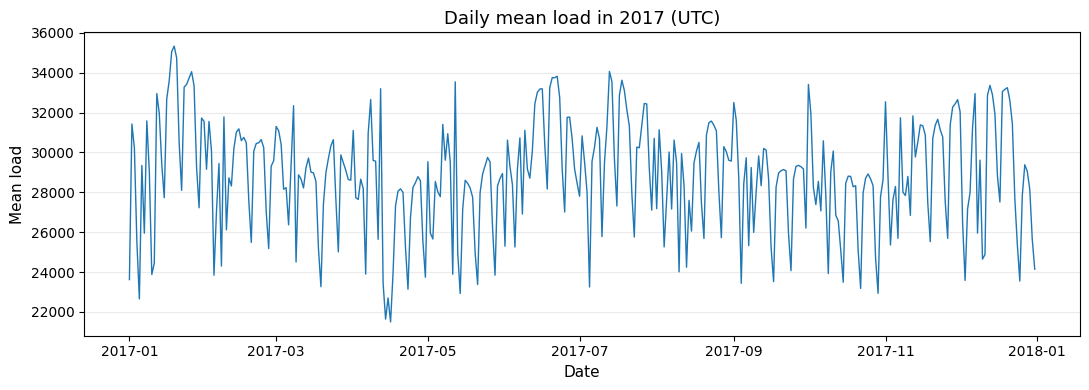

In [2]:
plt.figure(figsize=(11, 4))
plt.plot(
    daily_2017.index,
    daily_2017["total load actual"],
    color="tab:blue", linewidth=1,
)
plt.title("Daily mean load in 2017 (UTC)")
plt.xlabel("Date")
plt.ylabel("Mean load")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 02. fig 和 ax：一张图上叠加两组数据


    `fig` 是整张画布，`ax` 是其中一个绘图区。`plt.subplots()` 只有一个子图时，`ax` 是单个对象。
    在同一个 `ax` 上调用两次 `plot()`，就会叠加两条线。
    两个变量单位相同，可共用纵轴。`label=` 配合 `ax.legend()` 显示图例。

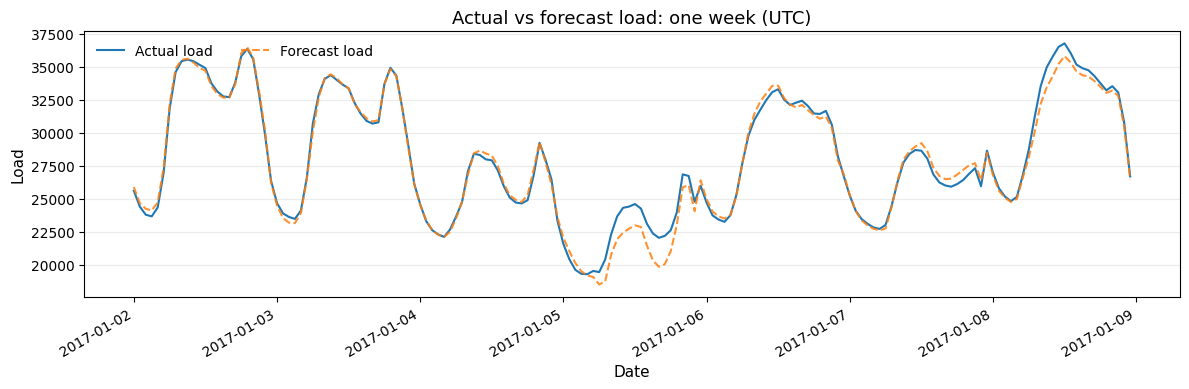

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(week.index, week["total load actual"],
        label="Actual load", color="tab:blue", linewidth=1.5)
ax.plot(week.index, week["total load forecast"],
        label="Forecast load", color="tab:orange", linestyle="--", alpha=0.85)
ax.set_title("Actual vs forecast load: one week (UTC)")
ax.set_xlabel("Date")
ax.set_ylabel("Load")
ax.legend(loc="upper left", ncol=2, frameon=False)
ax.grid(axis="y", alpha=0.25)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()

## 03. 折线样式：点、颜色、线型，以及两组日内曲线


    工作日与周末分别按 UTC 小时取均值，在同一张图对比。
    常用参数：`color` 颜色、`linestyle` 线型、`linewidth` 线宽、`marker` 数据点、`alpha` 透明度。
    `set_xticks()` 设置刻度位置；它不会改变分组数据。

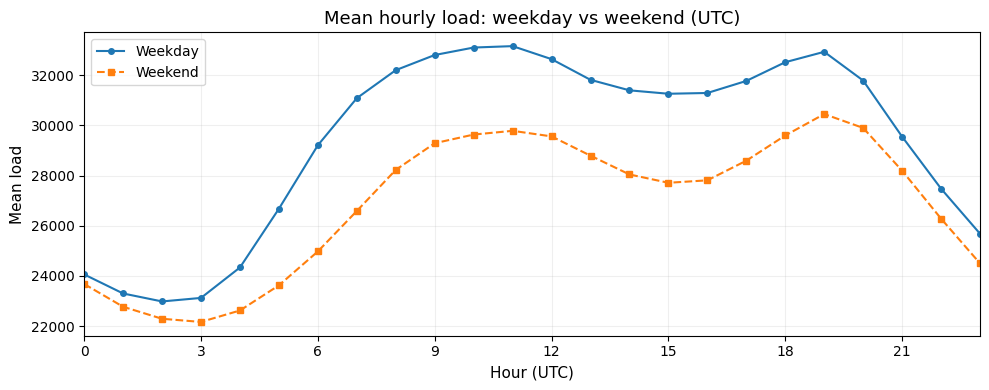

is_weekend,False,True
hour,,
0,24060.914669,23679.454545
1,23301.114203,22771.868106
2,22983.304890,22292.433014
3,23124.205374,22166.736842
4,24337.919463,22623.203349
5,26679.190979,23624.976077
6,29210.463977,24977.702638
7,31087.029808,26589.398082
8,32204.603647,28227.850962


In [2]:
profile_data = df[["total load actual"]].copy()
profile_data["hour"] = profile_data.index.hour
profile_data["is_weekend"] = profile_data.index.dayofweek >= 5
hourly_compare = profile_data.groupby(
    ["hour", "is_weekend"]
)["total load actual"].mean().unstack("is_weekend")

fig, ax = plt.subplots()
ax.plot(hourly_compare.index, hourly_compare[False],
        marker="o", markersize=4, label="Weekday", color="tab:blue")
ax.plot(hourly_compare.index, hourly_compare[True],
        marker="s", markersize=4, linestyle="--",
        label="Weekend", color="tab:orange")
ax.set(title="Mean hourly load: weekday vs weekend (UTC)",
       xlabel="Hour (UTC)", ylabel="Mean load")
ax.set_xticks(range(0, 24, 3))
ax.set_xlim(0, 23)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
display(hourly_compare)

## 04. hist：看单个变量的分布


    `hist()` 的横轴是价格区间，纵轴默认是样本数量。`bins` 控制分箱数量。
    这与每个类别一根柱子的 `bar()` 含义不同。先试 `bins=10`，再试 `bins=60`，观察细节变化。

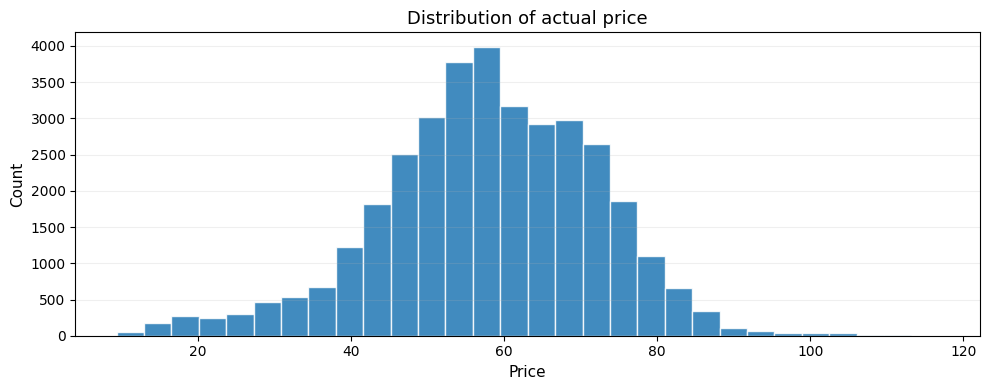

In [5]:
values = df["price actual"].dropna()
fig, ax = plt.subplots()
ax.hist(values, bins=30, color="tab:blue", edgecolor="white", alpha=0.85)
ax.set(title="Distribution of actual price", xlabel="Price", ylabel="Count")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 05. 同一张图叠加两组直方图


    用相同的 `bins` 边界公平比较两个分布，`alpha` 让重叠部分可见。
    `density=True` 把总面积归一化为 1，纵轴是密度，不是某个价格的概率。

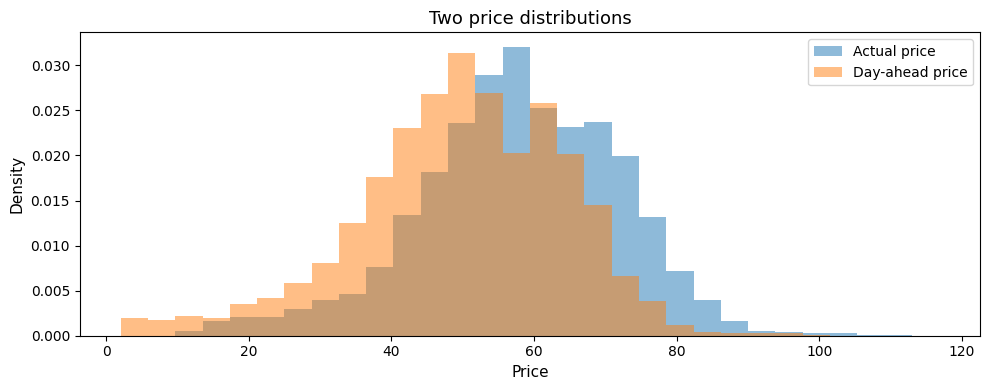

In [6]:
prices = df[["price actual", "price day ahead"]].dropna()
bins = np.linspace(prices.min().min(), prices.max().max(), 31)

fig, ax = plt.subplots()
ax.hist(prices["price actual"], bins=bins, density=True,
        alpha=0.5, label="Actual price", color="tab:blue")
ax.hist(prices["price day ahead"], bins=bins, density=True,
        alpha=0.5, label="Day-ahead price", color="tab:orange")
ax.set(title="Two price distributions", xlabel="Price", ylabel="Density")
ax.legend()
fig.tight_layout()
plt.show()

## 06. bar：类别对比、短标签、柱顶数值


    星期是有顺序的类别。柱高用于比较大小，纵轴从 0 开始。
    `bar_label()` 给每根柱子加数值，`padding` 调整文字距离。
    类别显示为缩写，数据中完整的星期名称不变。

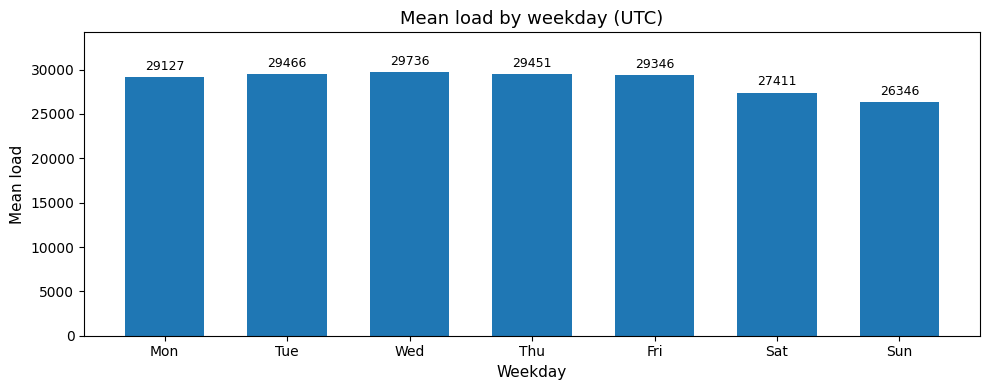

In [4]:
positions = np.arange(len(weekday_load))
short_days = [name[:3] for name in weekday_load.index]

fig, ax = plt.subplots()
bars = ax.bar(short_days, weekday_load.values, color="tab:blue", width=0.65)
# ax.set_xticks(positions)
# ax.set_xticklabels(short_days)
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
ax.set_ylim(0, weekday_load.max() * 1.15)
ax.set(title="Mean load by weekday (UTC)", xlabel="Weekday", ylabel="Mean load")
fig.tight_layout()
plt.show()

## 07. 分组柱状图：两组柱子并排对比


    用数字表示每组的位置，再给两组柱子各加减半个柱宽。
    如果都用同一个 x 位置，两组柱子会重叠。这里比较每个星期几的实际负荷与预测负荷。

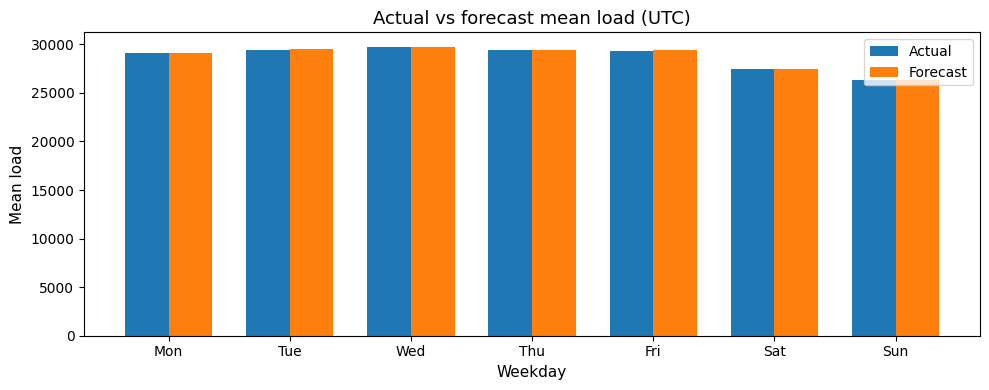

time
Monday       29112.698305
Tuesday      29469.764223
Wednesday    29747.558382
Thursday     29460.556220
Friday       29396.714314
Saturday     27430.092504
Sunday       26375.978469
Name: total load forecast, dtype: float64

In [6]:
positions = np.arange(len(week_order))
width = 0.36



#正常的matplot会自动分配0-n，所以单个柱子没有影响，但是柱子多了，就会重叠，这个时候最好使用数值直接标记
fig, ax = plt.subplots()
ax.bar(positions - width / 2, weekday_compare["total load actual"],
       width=width, label="Actual", color="tab:blue")
ax.bar(positions + width / 2, weekday_compare["total load forecast"],
       width=width, label="Forecast", color="tab:orange")
ax.set_xticks(positions)
ax.set_xticklabels([name[:3] for name in week_order])
ax.set_ylim(bottom=0)
ax.set(title="Actual vs forecast mean load (UTC)",
       xlabel="Weekday", ylabel="Mean load")
ax.legend()
fig.tight_layout()
plt.show()
display(weekday_compare["total load forecast"])

## 08. barh：字段名很长时横过来画


    长列名用 `barh()` 通常更容易阅读。先排序再画，使大小关系直观。
    这里展示四个主要字段的缺失数量，零值也是有效的统计结果。

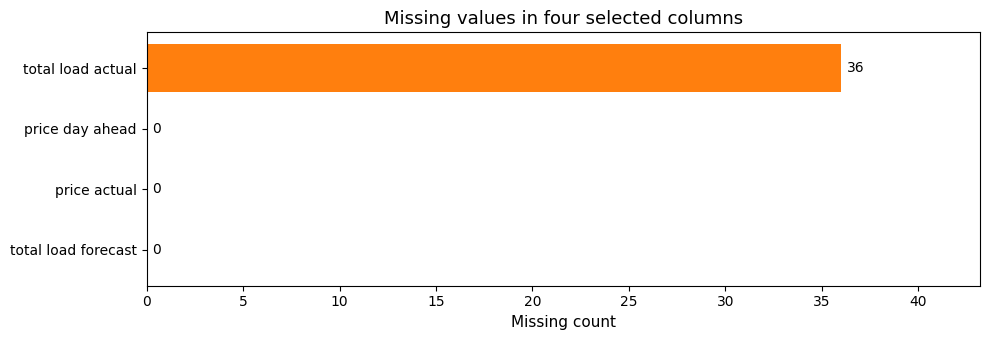

In [9]:
missing = df[core_columns].isna().sum().sort_values()
fig, ax = plt.subplots(figsize=(10, 3.5))
bars = ax.barh(missing.index, missing.values, color="tab:orange")
ax.bar_label(bars, padding=4)
ax.set_xlim(0, max(missing.max(), 1) * 1.2)
ax.set(title="Missing values in four selected columns", xlabel="Missing count")
fig.tight_layout()
plt.show()

## 09. scatter：两个变量是否一起变化


    每个点表示一个小时。横轴是负荷，纵轴是价格。
    为减少遮挡，仅抽取最多 2,000 条完整记录演示；`random_state` 保持每次抽样一致。
    `s` 是点的大小，`alpha` 是透明度。散点图中的相关形态不能直接证明因果。

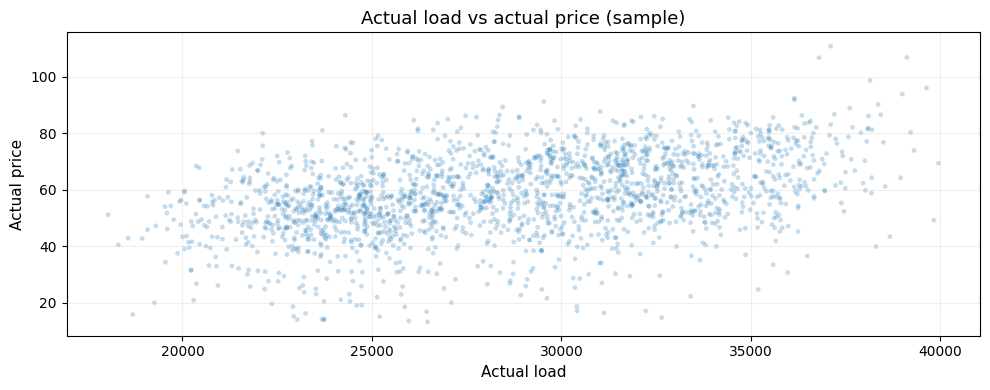

In [10]:
scatter_data = df[["total load actual", "price actual"]].dropna()
scatter_sample = scatter_data.sample(n=min(2000, len(scatter_data)), random_state=7)

fig, ax = plt.subplots()
ax.scatter(scatter_sample["total load actual"], scatter_sample["price actual"],
           s=12, alpha=0.25, color="tab:blue", edgecolors="none")
ax.set(title="Actual load vs actual price (sample)",
       xlabel="Actual load", ylabel="Actual price")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 10. boxplot：各月份的分布与波动


    每个月把所有非缺失小时负荷作为一组，跨年份合并。
    箱体表示第 25% 到第 75% 分位数，中线表示中位数。
    默认须线延伸到距箱体不超过 1.5 倍 IQR 的最远观测；须线外的点不是自动应删除的错误。
    尝试 `showfliers=False` 可以隐藏这些点，但不会删除数据。

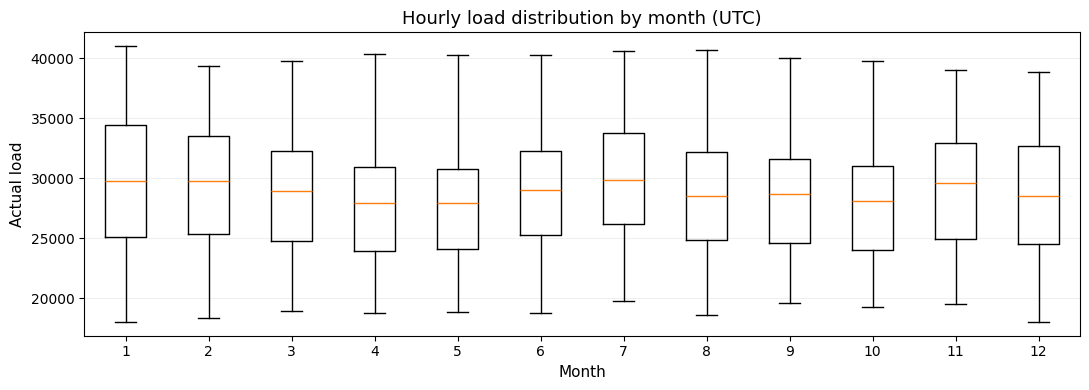

In [11]:
month_groups = [
    df.loc[df.index.month == month, "total load actual"].dropna().values
    for month in range(1, 13)
]

fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(month_groups, showfliers=True,
           flierprops={"markersize": 2, "alpha": 0.2})
ax.set_xticks(range(1, 13))
ax.set_xticklabels([str(month) for month in range(1, 13)])
ax.set(title="Hourly load distribution by month (UTC)",
       xlabel="Month", ylabel="Actual load")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 11. pie：饼图展示组成


    饼图适合少量非负类别的组成，不适合价格变化或变量相关关系。
    这里使用共同有记录的小时，计算四类发电量的均值，再展示它们之间的占比。
    **分母仅包含这四类，不能解释为完整的发电结构。**
    `autopct` 显示百分比，`startangle` 设置起始角度，`axis("equal")` 保持圆形。

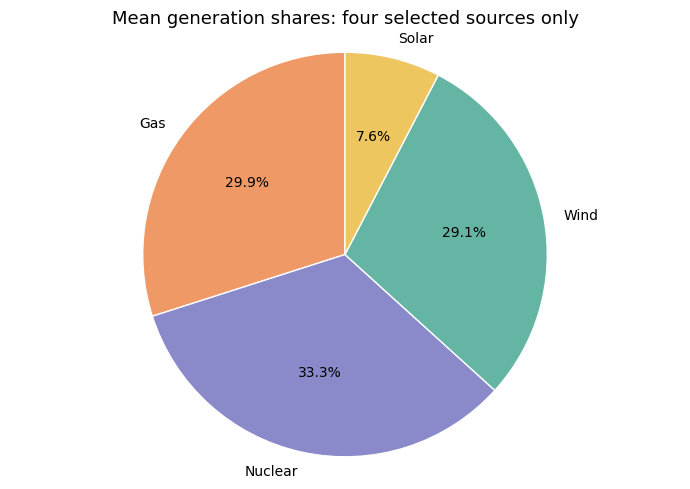

generation fossil gas      5622.737488
generation nuclear         6263.888233
generation wind onshore    5464.479769
generation solar           1432.665925
dtype: float64

In [8]:
generation_columns = [
    "generation fossil gas", "generation nuclear",
    "generation wind onshore", "generation solar",
]
generation_means = df[generation_columns].dropna().mean()
generation_labels = ["Gas", "Nuclear", "Wind", "Solar"]
generation_colors = ["#ee9966", "#8a8acb", "#65b5a5", "#edc65f"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.pie(generation_means, labels=generation_labels,
       autopct="%.1f%%", startangle=90, colors=generation_colors,
       wedgeprops={"edgecolor": "white"})
ax.set_title("Mean generation shares: four selected sources only")
ax.axis("equal")
fig.tight_layout()
plt.show()
display(generation_means)

## 12. 环形图：饼图中间留空，图例放到外侧


    环形图仍然使用 `pie()`，通过 `wedgeprops={"width": ...}` 控制圆环宽度。
    `bbox_to_anchor` 配合 `loc` 将图例放在绘图区外；为图例留出右侧空间。

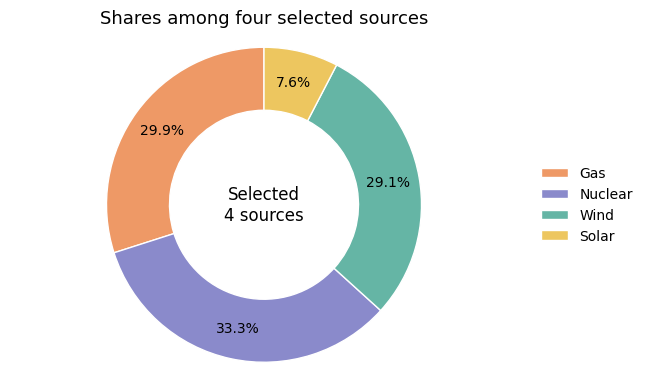

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
wedges, texts, percentages = ax.pie(
    generation_means.values, labels=None, autopct="%.1f%%",
    startangle=90, pctdistance=0.8, colors=generation_colors,
    wedgeprops={"width": 0.4, "edgecolor": "white"},
)
ax.text(0, 0, "Selected\n4 sources", ha="center", va="center", fontsize=12)
ax.legend(wedges, generation_labels, loc="center left",
          bbox_to_anchor=(1.02, 0.5), frameon=False)
ax.set_title("Shares among four selected sources")
ax.axis("equal")
fig.subplots_adjust(right=0.76)
plt.show()

## 刻度之前，先区分三种东西

| 名称 | 含义 | 修改方法 |
|---|---|---|
| 数据的 `index` | pandas 中每行的标签，例如时间或星期 | `set_index()`、`sort_index()`、`reindex()` |
| 刻度位置 | 坐标轴上在哪些位置画小刻度 | `ax.set_xticks(...)` |
| 刻度标签 | 小刻度旁显示什么文字 | `ax.set_xticklabels(...)` / formatter |

改显示文字不会改变数据。`reindex()` 按已有标签匹配，不是给数字索引自动换名字。
对星期名称排序时，先用 `day_name()` 分组，再 `reindex(week_order)`。

## 13. 索引与横轴：不传 x 会发生什么


    左图只传入数值，Matplotlib 用 0、1、2……作为横轴。
    右图明确传入日期索引，横轴才表达真实日期。
    两张图的 y 完全相同；这里不修改原始索引。

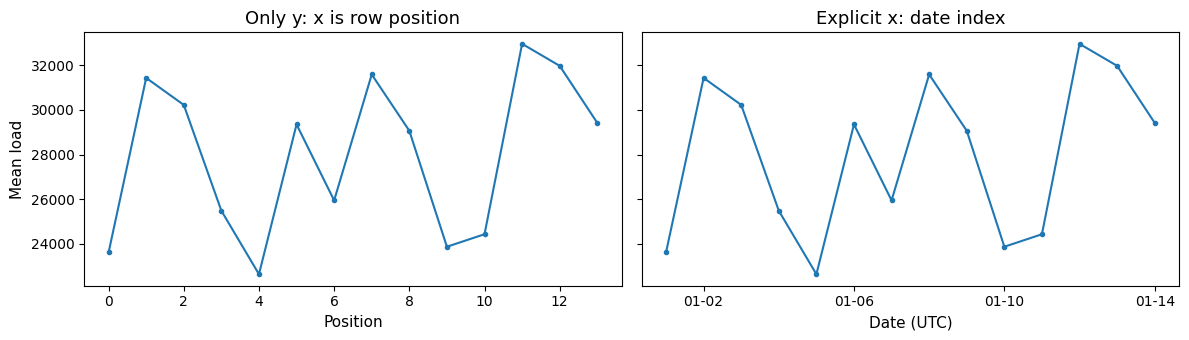

In [14]:
selected = daily_2017["total load actual"].iloc[:14]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
axes[0].plot(selected.values, marker="o", markersize=3)
axes[0].set(title="Only y: x is row position", xlabel="Position", ylabel="Mean load")
axes[1].plot(selected.index, selected.values, marker="o", markersize=3)
axes[1].set(title="Explicit x: date index", xlabel="Date (UTC)")
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=4))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
fig.tight_layout()
plt.show()

## 14. 日期太密：减少日期刻度并格式化


    日期轴通常不需要手动给每一行设置标签。
    左图每两个月显示一次，右图让 Matplotlib 自动选择并简化日期显示。
    `rotation` 旋转文字，`tight_layout()` 给标题和标签留空间。

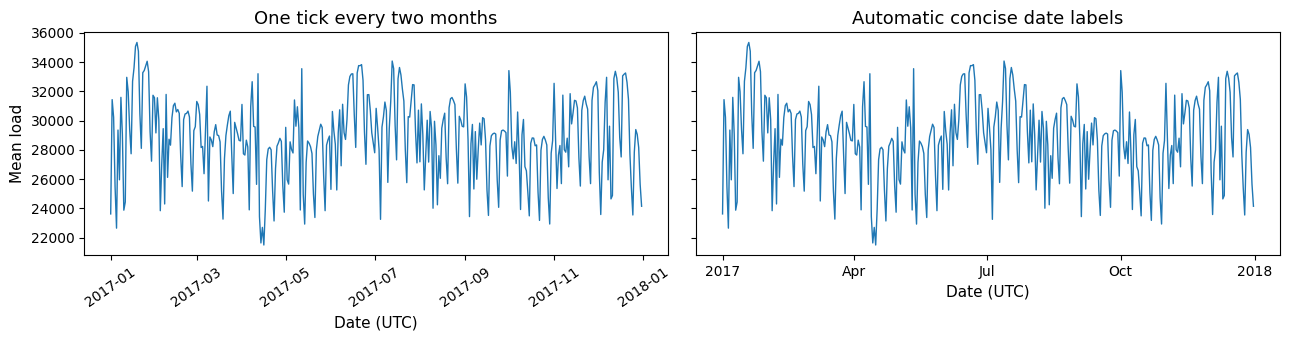

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for ax in axes:
    ax.plot(daily_2017.index, daily_2017["total load actual"], linewidth=1)
    ax.set_xlabel("Date (UTC)")

axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[0].tick_params(axis="x", labelrotation=35)
axes[0].set_title("One tick every two months")
axes[0].set_ylabel("Mean load")

locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[1].set_title("Automatic concise date labels")
fig.tight_layout()
plt.show()

## 15. 数字刻度：每隔三小时显示一个值


    `MultipleLocator(3)` 表示主刻度间隔为 3。
    `set_xlim()` 只控制看到的范围，不会改变均值计算，也不会删除原始记录。
    直接设置 `ax.set_xticks(range(0, 24, 3))` 也可以。

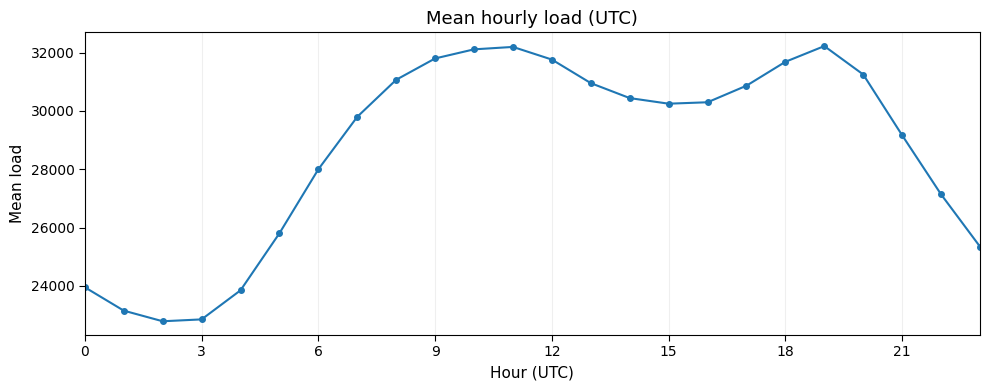

In [16]:
fig, ax = plt.subplots()
ax.plot(hourly_load.index, hourly_load.values, marker="o", markersize=4)
ax.xaxis.set_major_locator(MultipleLocator(3))
ax.set_xlim(0, 23)
ax.set(title="Mean hourly load (UTC)", xlabel="Hour (UTC)", ylabel="Mean load")
ax.tick_params(axis="both", labelsize=10, length=4)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

## 16. 纵轴数字更好看：千分位或 k 单位


    `FuncFormatter` 只改变显示文字，数据本身仍然是原来的数值。
    左图显示 `30,000`，右图显示 `30.0k`；右图轴名称说明使用了千单位。
    若出现不想要的科学计数法，可在默认数字轴上使用
    `ax.ticklabel_format(axis="y", style="plain", useOffset=False)`。

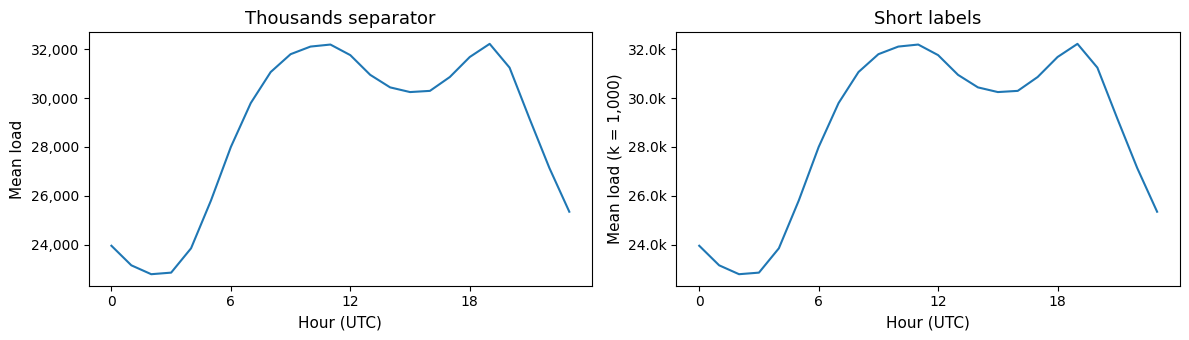

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax in axes:
    ax.plot(hourly_load.index, hourly_load.values)
    ax.set_xlabel("Hour (UTC)")
    ax.set_xticks(range(0, 24, 6))

axes[0].yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))
axes[0].set(title="Thousands separator", ylabel="Mean load")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value / 1000:.1f}k"))
axes[1].set(title="Short labels", ylabel="Mean load (k = 1,000)")
fig.tight_layout()
plt.show()

## 17. 隐藏 x / y 的文字、刻度或整个坐标轴


    三张图使用相同数据，对比三种隐藏方式。

    - **仅隐藏刻度文字**：`tick_params(labelbottom=False, labelleft=False)`，保留刻度线。
    - **同时隐藏刻度线与文字**：再加 `bottom=False, left=False`。
    - **隐藏整个坐标框架**：`ax.set_axis_off()`，适合装饰性小图。

    其他常用写法：`ax.set_xticks([])` 删除 x 主刻度；`ax.set_yticks([])` 删除 y 主刻度；
    `ax.set_xlabel("")` 只移除轴名称；`ax.spines["top"].set_visible(False)` 隐藏上边框。
    在正式数据图中，隐藏后仍需让读者能理解量纲和尺度。

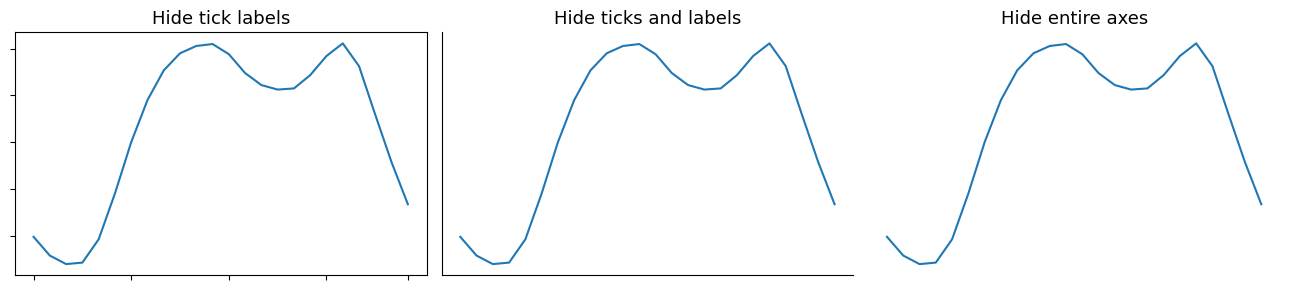

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharex=True, sharey=True)
for ax in axes:
    ax.plot(hourly_load.index, hourly_load.values)
    ax.set_xticks([0, 6, 12, 18, 23])

axes[0].tick_params(axis="both", labelbottom=False, labelleft=False)
axes[0].set_title("Hide tick labels")

axes[1].tick_params(axis="both", bottom=False, left=False,
                    labelbottom=False, labelleft=False)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].set_title("Hide ticks and labels")

axes[2].set_axis_off()
axes[2].set_title("Hide entire axes")
fig.tight_layout()
plt.show()

## 18. 同一组数据：纵轴范围如何影响观感


    左右都是同一份星期平均负荷。左边从 0 开始，右边只展示局部范围。
    折线使用局部纵轴有助于看细节，但会让相对变化显得更大，解释时应报告实际差值或百分比。
    柱状图依靠柱长比较数值，一般让纵轴从 0 开始。

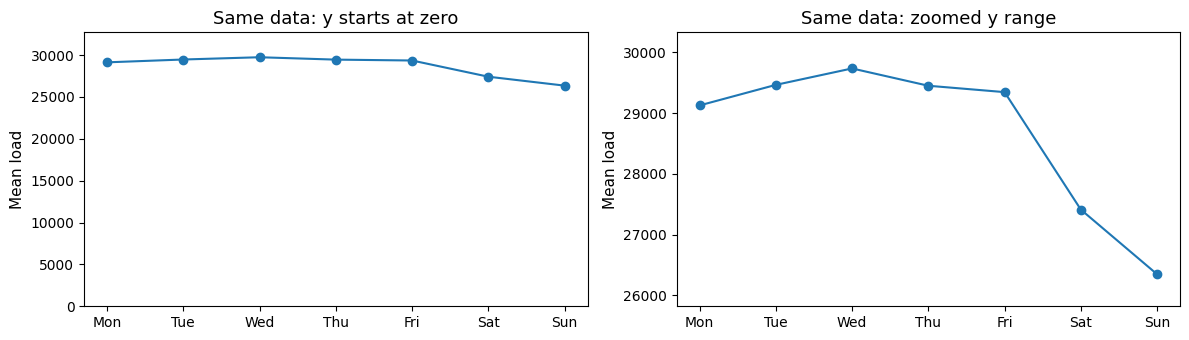

In [19]:
positions = np.arange(len(weekday_load))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax in axes:
    ax.plot(positions, weekday_load.values, marker="o")
    ax.set_xticks(positions)
    ax.set_xticklabels([name[:3] for name in week_order])
    ax.set_ylabel("Mean load")

axes[0].set_ylim(0, weekday_load.max() * 1.1)
axes[0].set_title("Same data: y starts at zero")
axes[1].set_ylim(weekday_load.min() * 0.98, weekday_load.max() * 1.02)
axes[1].set_title("Same data: zoomed y range")
fig.tight_layout()
plt.show()

## 19. 一张画布放四张图：2 × 2 子图


    `plt.subplots(2, 2)` 返回二维 `axes`：用 `axes[0, 0]` 选左上角，`axes[1, 1]` 选右下角。
    `axes.flat` 可以依次遍历所有子图。四幅图量纲不同，各自设置纵轴。
    `fig.suptitle()` 是整张画布的总标题，`ax.set_title()` 是单个子图的标题。

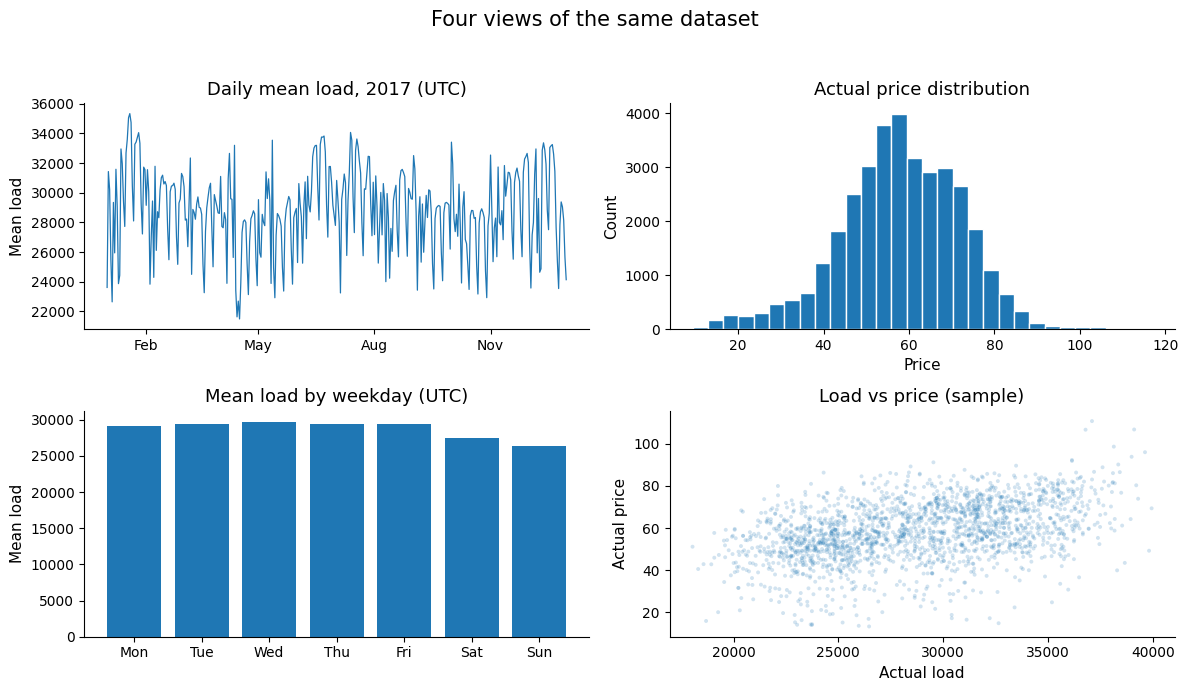

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

axes[0, 0].plot(daily_2017.index, daily_2017["total load actual"], linewidth=0.9)
axes[0, 0].set(title="Daily mean load, 2017 (UTC)", ylabel="Mean load")
axes[0, 0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[0, 0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))

axes[0, 1].hist(df["price actual"].dropna(), bins=30, edgecolor="white")
axes[0, 1].set(title="Actual price distribution", xlabel="Price", ylabel="Count")

axes[1, 0].bar([name[:3] for name in week_order], weekday_load.values)
axes[1, 0].set(title="Mean load by weekday (UTC)", ylabel="Mean load")

axes[1, 1].scatter(scatter_sample["total load actual"], scatter_sample["price actual"],
                   s=8, alpha=0.2, edgecolors="none")
axes[1, 1].set(title="Load vs price (sample)", xlabel="Actual load", ylabel="Actual price")

for ax in axes.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Four views of the same dataset", fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 20. 上下对齐比较：共享 x 轴，不共享 y 轴


    负荷和价格使用相同时间轴，上下放置可直接对齐时刻。
    `sharex=True` 会同步横轴范围，并默认隐藏上图重复的 x 刻度文字。
    两组变量单位不同，所以各用各的纵轴。

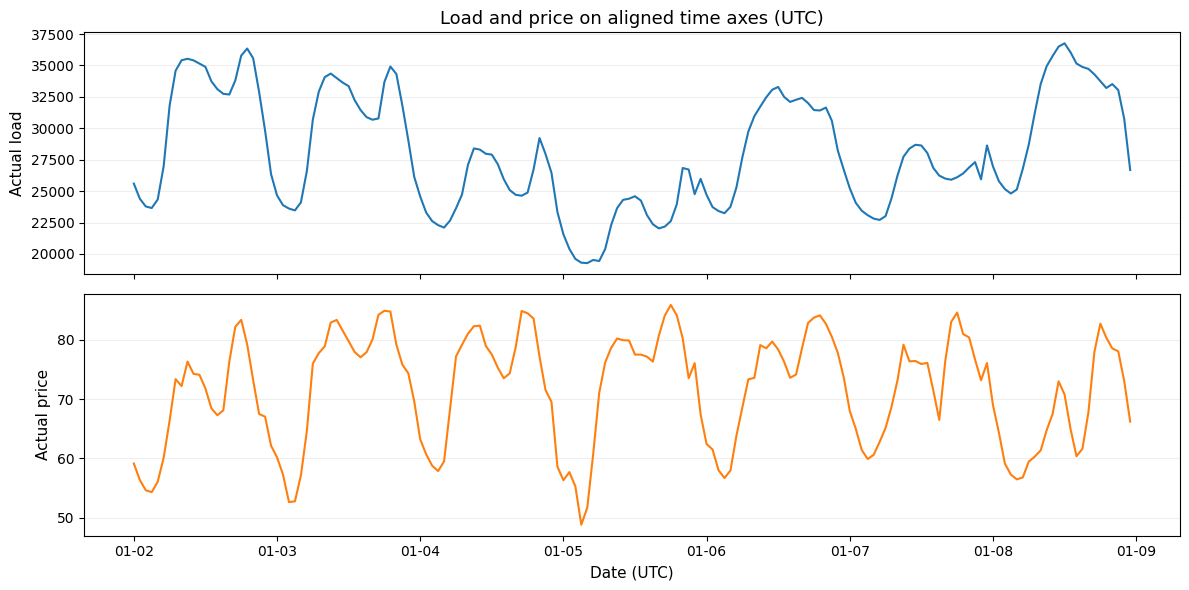

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(week.index, week["total load actual"], color="tab:blue")
axes[0].set(title="Load and price on aligned time axes (UTC)", ylabel="Actual load")
axes[1].plot(week.index, week["price actual"], color="tab:orange")
axes[1].set(ylabel="Actual price", xlabel="Date (UTC)")

axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=1))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 21. twinx：同一张图、两套纵轴


    `ax.twinx()` 创建共享 x 轴的新绘图区：负荷用左轴，价格用右轴。
    让轴标签颜色与曲线颜色一致，并手动合并两条线的图例。
    两套纵轴的范围可以任意调整，线看起来重合不代表相关性高；对齐子图往往更容易解释。

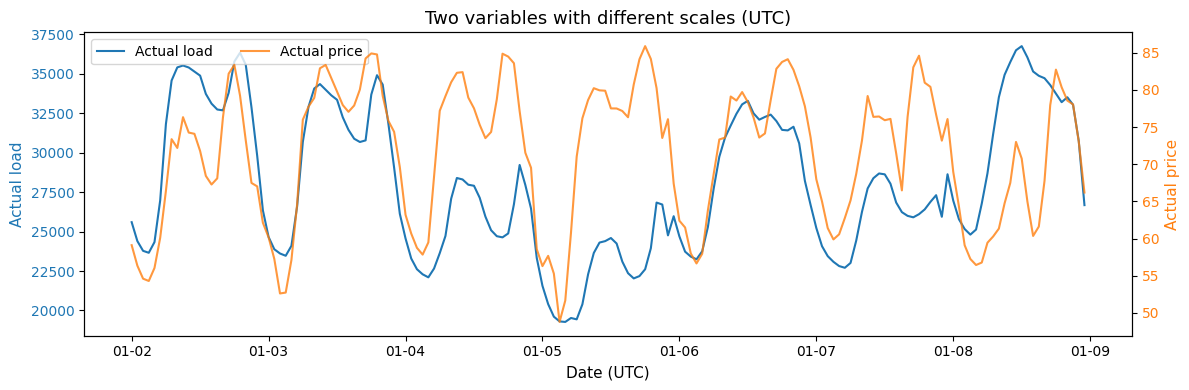

In [22]:
fig, ax_load = plt.subplots(figsize=(12, 4))
ax_price = ax_load.twinx()

line_load, = ax_load.plot(week.index, week["total load actual"],
                          color="tab:blue", label="Actual load")
line_price, = ax_price.plot(week.index, week["price actual"],
                            color="tab:orange", label="Actual price", alpha=0.8)
ax_load.set_ylabel("Actual load", color="tab:blue")
ax_price.set_ylabel("Actual price", color="tab:orange")
ax_load.tick_params(axis="y", labelcolor="tab:blue")
ax_price.tick_params(axis="y", labelcolor="tab:orange")
ax_load.set(title="Two variables with different scales (UTC)", xlabel="Date (UTC)")
ax_load.legend(handles=[line_load, line_price], loc="upper left", ncol=2)
ax_load.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
fig.tight_layout()
plt.show()

## 22. 参考线、区域高亮和箭头标注


    `axhline()` 画水平线；`axvline()` 画竖线；`axvspan()` 高亮一段横轴区间。
    `annotate()` 的 `xy` 是要指出的数据坐标，`xytext` 在这里使用相对于它的点数偏移（points）。
    这一例标出 2017 年最高的每日平均负荷，并用阴影突出七月。

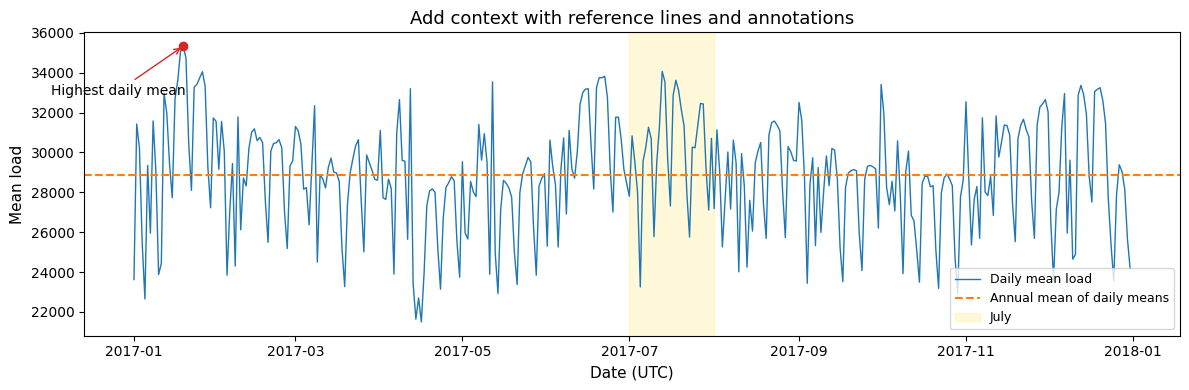

In [23]:
values = daily_2017["total load actual"].dropna()
peak_time = values.idxmax()
peak_value = values.max()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(values.index, values.values, linewidth=1, label="Daily mean load")
ax.axhline(values.mean(), color="tab:orange", linestyle="--", label="Annual mean of daily means")
ax.axvspan(pd.Timestamp("2017-07-01", tz="UTC"),
           pd.Timestamp("2017-08-01", tz="UTC"),
           color="gold", alpha=0.15, label="July")
ax.scatter([peak_time], [peak_value], color="tab:red", zorder=3)
ax.annotate("Highest daily mean", xy=(peak_time, peak_value),
            xytext=(-95, -35), textcoords="offset points",
            arrowprops={"arrowstyle": "->", "color": "tab:red"})
ax.set(title="Add context with reference lines and annotations", xlabel="Date (UTC)", ylabel="Mean load")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()

## 23. 保存图片：先保存，再 show


    `fig.savefig()` 保存这张指定的画布。先保存再 `show()`，便于明确保存的是哪张图。
    `dpi` 控制 PNG 清晰度，`bbox_inches="tight"` 减少外围空白并照顾外侧标签。
    运行此 cell 会在当前目录创建 `plot_examples_output/hourly_load.png`。

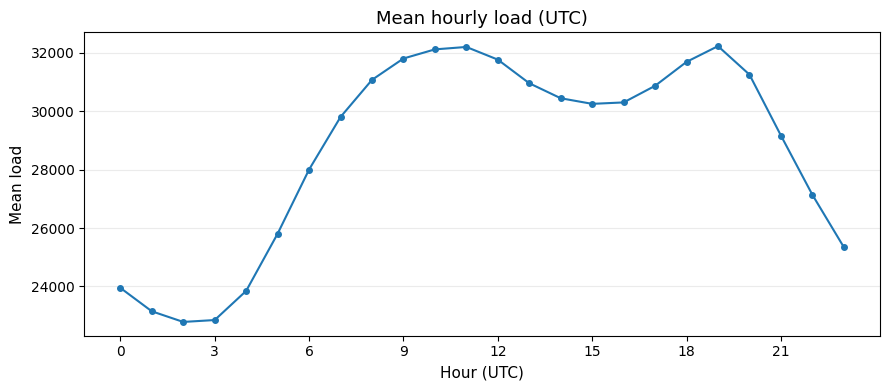

Saved: /Users/tianrensun/Downloads/python/SquarePoint/plot_examples_output/hourly_load.png


In [24]:
output_dir = Path("plot_examples_output")
output_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hourly_load.index, hourly_load.values, marker="o", markersize=4)
ax.set(title="Mean hourly load (UTC)", xlabel="Hour (UTC)", ylabel="Mean load")
ax.set_xticks(range(0, 24, 3))
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(output_dir / "hourly_load.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", (output_dir / "hourly_load.png").resolve())

## 最后留一份可复制的小模板

常规单图按下面的顺序写，通常就足够了：

```python
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x, y, label="My series")  # 换成 bar / scatter / hist 等

ax.set_title("Title")
ax.set_xlabel("X label")
ax.set_ylabel("Y label")
ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()
```

**多个子图的 axes 形状：**

```python
fig, ax = plt.subplots()            # 单个对象：ax.plot(...)
fig, axes = plt.subplots(1, 2)      # 一维：axes[0].plot(...)
fig, axes = plt.subplots(2, 2)      # 二维：axes[0, 1].plot(...)
```

**常见小问题：**

- 日期太密：减少刻度数量，再使用日期 formatter；不要给每条观测都设置一个标签。
- 文字挤在一起：缩写、适度旋转、增加画布宽度，再 `tight_layout()`。
- 图例没出现：绘图时设置 `label=`，然后调用 `ax.legend()`。
- 两条线完全重叠：确认数据是否相同或非常接近，可以改成虚线、加透明度或分成上下子图。
- `reindex()` 后全是 NaN：检查原索引和新标签是否一致；数字 0 与字符串 Monday 不会自动匹配。
- 画完没显示：在 notebook 中执行 `plt.show()`，并确认运行了该 cell。
- 缺失记录：不要为了让线连续而直接填零；先确定缺失处理方法。

**自己改一改：**

1. 把第 03 节的小时刻度改成每 2 小时一个，周末改成红色虚线。
2. 把第 05 节的直方图改成上下两个子图，并统一 x 轴范围。
3. 在第 06 节保留星期文字，隐藏纵轴刻度文字，观察柱顶数值是否足够解释图。
4. 把第 19 节的 2 × 2 布局改成 4 × 1，为整张图增加高度。

## 24. set_major_formatter：设置刻度文字的显示格式

`ax.xaxis.set_major_formatter(...)` 设置 **x 轴主刻度旁的文字怎么显示**。
它不改变数据，也不决定刻度放在哪里；刻度位置由 locator 控制。
同样的规则可以用于 `ax.yaxis.set_major_formatter(...)`。

### 日期轴：DateFormatter

`mdates` 是 `matplotlib.dates` 的简称，用来处理日期坐标。

```python
import matplotlib.dates as mdates

# 日期显示为 01-02
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
```

常用格式，选择一种即可：

| 格式 | 示例 |
|---|---|
| `"%Y-%m-%d"` | `2017-01-02` |
| `"%Y-%m"` | `2017-01` |
| `"%m-%d"` | `01-02` |
| `"%H:%M"` | `06:00` |

### 普通数字轴：FuncFormatter

比如 x 的值是 0—1000，可以自定义显示方式。下面两种选择一种即可：

```python
from matplotlib.ticker import FuncFormatter

# 1000 显示为 1,000
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:,.0f}")
)
```

```python
# 1000 显示为 1.0k；原始数据仍然是 1000
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value / 1000:.1f}k")
)
```

`value` 是当前刻度数值，`position` 是刻度序号；这里用不到 `position`，但函数需要接收两个参数。

**简写：固定小数位也可以直接传格式字符串。**

```python
# 12 显示为 12.0
ax.yaxis.set_major_formatter("{x:.1f}")
```

这些设置放在画图之后、`plt.show()` 之前。显示多少个刻度、每隔多远一个，仍由 locator 决定。


### 横轴刻度被自动省略：自己控制显示哪些值

Matplotlib 会自动选择部分刻度，数据点仍然保留。**locator 控制刻度位置，formatter 控制显示文字。**

**方式一：精确指定刻度位置。**

```python
ax.set_xticks([0, 100, 200, 500, 1000])
```

**方式二：普通数字轴，固定间隔。**

```python
from matplotlib.ticker import MultipleLocator

# 每隔 100 显示一个主刻度
ax.xaxis.set_major_locator(MultipleLocator(100))
```

**方式三：日期轴，每天一个刻度，并显示为月-日。**

```python
import matplotlib.dates as mdates

ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
```

文字拥挤时可以旋转：

```python
ax.tick_params(axis="x", labelrotation=45)
```

以上是不同场景的用法，按需要选择，放在画图之后、`plt.show()` 之前。
同一个轴重复设置 locator 时，最后一次生效；`set_xticks()` 也会替换刻度位置规则。
若手动指定的刻度超出原显示范围，范围可能被扩展，需要时最后再调用 `ax.set_xlim(...)`。
